# Linnaeus University
## Introduction to Machine learning, 25VT-2DV516
## Assignment 1

**Name:** Maria Drambyan

**Email:** md223sd@student.lnu.se

## Introduction

In this assignment you will handle four exercises related to the k-Nearest Neighbors algorithm.
The main purpose is to get you up and running using Python, NumPy and Matplotlib. 
The library Scipy will be used specifically in Exercise 3, part 2.

## Submission Instructions

All exercises are individual. We expect you to submit a zip file with this notebook with your solutions and the MachineLearning.py with the models implemented. 
You must normalize your data before doing anything with your data.
When grading your assignments we will in addition to functionality also take into account code quality. 
We expect well structured and efficient solutions. 
Finally, keep all your files in a single folder named as username_A1 and submit a zipped version of this folder.

### Exercise 1: Models implementation and testing (All Mandatory)

1. Implement all the methods in the abstract classes **KNNRegressionModel** and **KNNClassificationModel** in the MachineLearningModel.py file. 
As the names suggest, you must implement the Regression (slide 30) and Classification (slide 24) versions of the KNN algorithm and you must follow the algorithms stated in the slides. 
* Both models must use the Euclidean distance as the distance function (*Tip: Code smart by implementing an auxiliary method _euclidian_distance() in the MachineLearningModel.py file*).
* The evaluate() function for the **KNNRegressionModel** must implement the Mean Squared Error (MSE)
* The evaluate() function for the **KNNClassificationModel** must count the number of correct predictions.

2. Use the *Polynomial200.csv* dataset to show that all your methods for the **KNNRegressionModel** is working as expected. You must produce a similar figure to the one in slide 31. Instructions to produce the figure are present in the slide. You must show the effects of using k = 3, 5, 7 and 9 and discuss your findings on the figure produced.

**Discuss your findings for this question below**

By looking at the graphs for different k, we can see how the number of neighbors affects the KNN regresion. For example for k = 3 the model fits the data very closely, but that's not really good as that can lead to overfitting. When we increase the k to 5 and 7 the curve becomes smoother, which shows that it got better at not overfitting and generalizing. For k=9 the curves becomes even smoother which means that even though it won't overfit but it might also underfit the data by loosing some details.


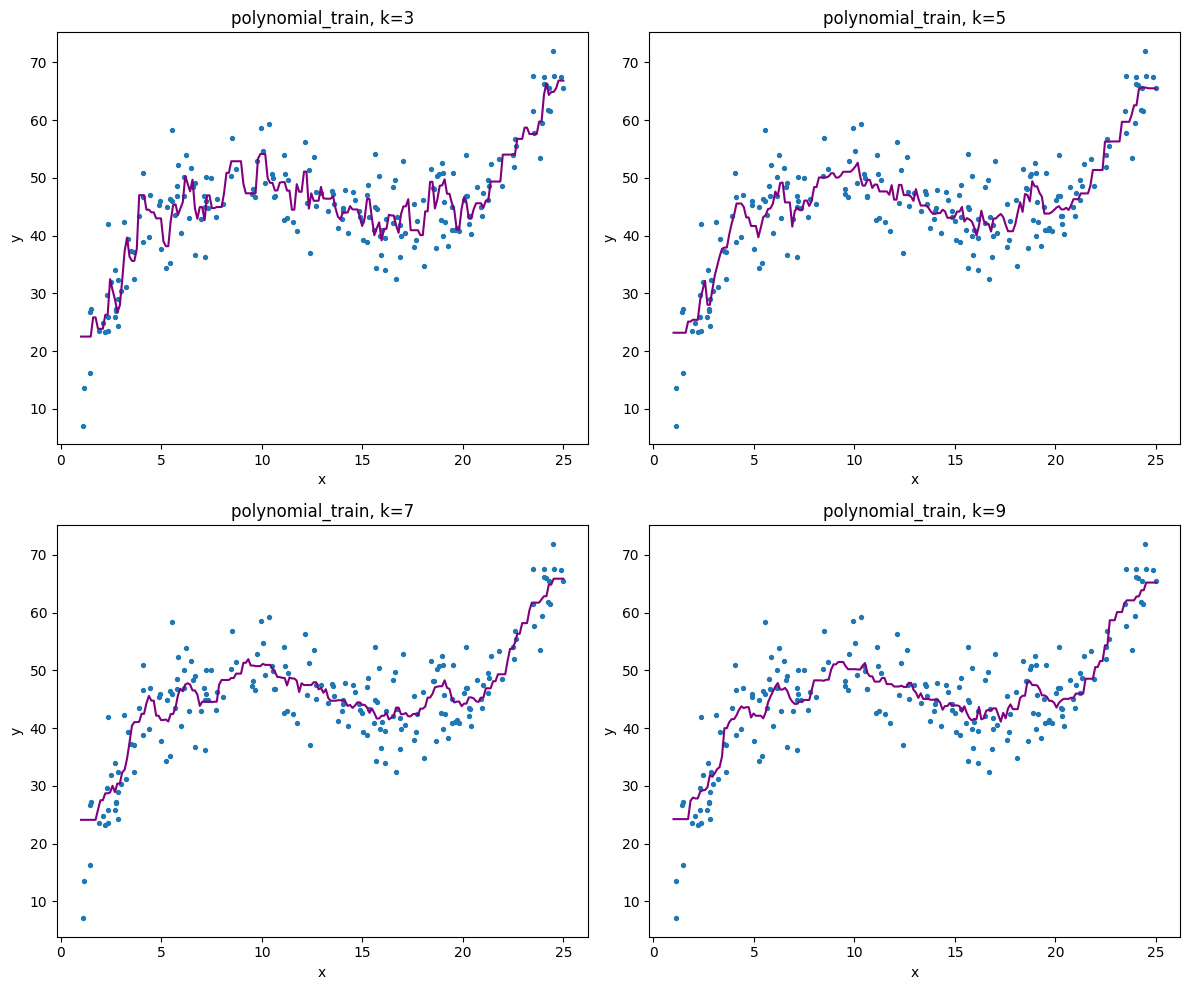

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("Polynomial200.csv", delimiter=",", skip_header=1)
X = data[:, 0]
y = data[:, 1]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

X_train = X[: int(len(X) * 0.8)]
y_train = y[: int(len(y) * 0.8)]

X_train_norm = X_norm[: int(len(X) * 0.8)]

X_predict = np.linspace(1, 25, 200)
X_predict_norm = (X_predict - X_mean) / X_std

fig, axis =  plt.subplots(2, 2, figsize=(12, 10))
axis = axis.ravel()

for i, k in enumerate([3, 5, 7, 9]):
    knn = mlm.KNNRegressionModel(k)
    knn.fit(X_train_norm, y_train)
    prediction = knn.predict(X_predict_norm)
    
    axis[i].scatter(X, y, s=8)
    axis[i].plot(X_predict, prediction, color='purple')
    axis[i].set_xlabel("x")
    axis[i].set_ylabel("y")
    axis[i].set_title(f"polynomial_train, k={k}")

plt.tight_layout()
plt.show()



3. Use the *IrisDataset.csv* dataset to show that all your methods for the **KNNClassificationModel** is working as expected. You must produce a similar figure to the one in slide 28. Instructions on how to produce the figure are given in the slide. You must choose 2 input variables only to produce the figure (they do not need to match the figure in the slide). You must show the effects of using k = 3, 5, 7, and 9 and discuss the figure produced.

**Tips**

* Check the function *np.meshgrid* from numpy to create the samples.
* Check the function *plt.contourf* for generating the countours. 
* There are many tutorials online to produce this figure. Find one that most suits you.

**Discuss your findings for this question below**

By looking at the plots we can see how the KNN algorithm's decision boundaries change with different k values. For k = 3 the boundaries are very flexible and they follow the training data very closely, which leads to overfitting. For k = 5,7 the boundaries become smoother, which means that they become better at generalization. For k = 9 the boundaries become too smooth, which leads to underfitting.

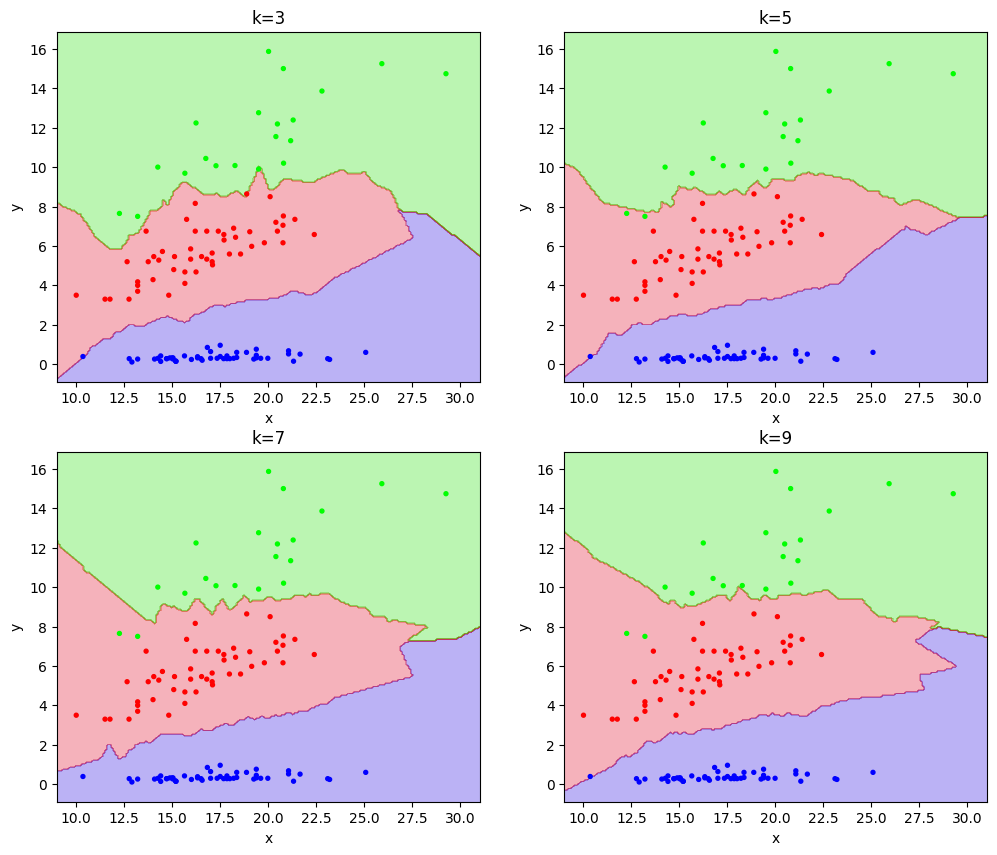

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("IrisDataset.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')
X = np.array([[r[0]*r[1], r[2]*r[3]] for r in data])
y = np.array([r[4] for r in data])

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

unique_labels = np.unique(y)
label_to_int = {label: i for i, label in enumerate(unique_labels)}
y = np.array([label_to_int[label] for label in y])

X_train = X[: int(len(X) * 0.8)]
y_train = y[: int(len(y) * 0.8)]
X_train_norm = X_norm[: int(len(X) * 0.8)]

X1_predict, X2_predict = np.meshgrid(np.linspace(X[ :,0].min() - 1, X[ :,0].max() + 1, 200),
                        np.linspace(X[ :,1].min() - 1, X[ :,1].max() + 1, 200))

X_predict = np.column_stack((X1_predict.flatten(), X2_predict.flatten()))
X_predict_norm = (X_predict - X_mean) / X_std

fig, axis =  plt.subplots(2, 2, figsize=(12, 10))
axis = axis.ravel()

for i, k in enumerate([3, 5, 7, 9]):
    knn = mlm.KNNClassificationModel(k)
    knn.fit(X_train_norm, y_train)
    prediction = knn.predict(X_predict_norm)

    axis[i].contourf(X1_predict, X2_predict, prediction.reshape(X1_predict.shape), alpha=0.3, cmap=plt.cm.brg)
    axis[i].scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=8, cmap=plt.cm.brg)
    axis[i].set_xlabel("x")
    axis[i].set_ylabel("y")
    axis[i].set_title(f"k={k}")

plt.show()


### Exercise 2: KNN Regression (Mandatory)

1. (Mandatory) Create a procedure to repeat 10 times the following strategy.
* Use the values for k = 3, 5, 7, 9, 11, 13 and 15.
* Split your dataset randomly into 80% for training, and 20% testing. Use 10 different seeds for splitting the data.
* Evaluate (MSE implemented in your class) your **KNNRegressionModel** for each k in the **test set** and store the result. 
* Plot a barchart with these results.

Which k gives the best regression? Motivate your answer!

**Discuss your findings for this question below**

By looking at the chart, k=11 gives the lowest mean MSE (around 30.35), indicating it performs best among the tested values. When k is smaller (like 3), we likely see a higher MSE because the model may be overfitting the noise in the data (it relies too heavily on very few neighbors). But when k is too large (e.g., 15), the model may smooth out local variations too much, causing a slight increase in MSE.


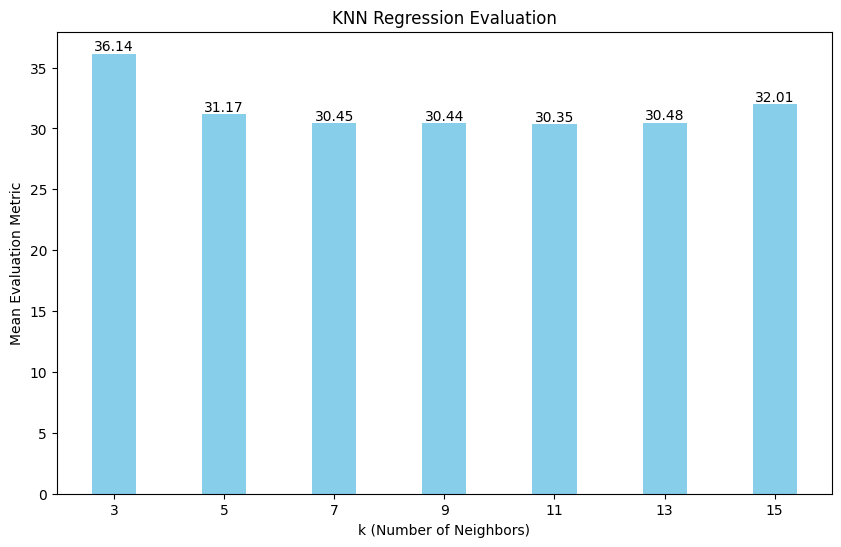

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("Polynomial200.csv", delimiter=",", skip_header=1)
X = data[:, 0]
y = data[:, 1]

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

seed = 65
k_values = [3, 5, 7, 9, 11, 13, 15]
results = {k: [] for k in k_values}

for i in range(10):
    np.random.seed(seed + i)
    
    indices = np.random.permutation(len(X_norm))
    X_norm = X_norm[indices]
    y = y[indices]
    
    X_train = X_norm[: int(len(X_norm) * 0.8)]
    y_train = y[: int(len(y) * 0.8)]
    
    X_test = X_norm[int(len(X_norm) * 0.8) :]
    y_test = y[int(len(y) * 0.8) :]
    
    for k in k_values:
        knn = mlm.KNNRegressionModel(k)
        knn.fit(X_train, y_train)
        prediction = knn.predict(X_test)
        results[k].append(knn.evaluate(y_test, prediction))
        
mean_results = {k: np.mean(results[k]) for k in k_values}

plt.figure(figsize=(10, 6))
bars = plt.bar(mean_results.keys(), mean_results.values(), color='skyblue')
plt.xticks(k_values)
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Mean Evaluation Metric")
plt.title("KNN Regression Evaluation")

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height, f'{height:.2f}', ha='center', va='bottom')
    
plt.show()

        

### Exercise 3: KNN Classification (1 Mandatory , 1 Non-Mandatory)

1. **(Mandatory)** Using the **IrisDataset.csv**, find the best combination of two features that produces the best model using **KNNClassificationModel**.
* You must try all combinations of two features, and for k = 3, 5, 7, and 9.
* You must use plots to support your answer.

**Discuss your findings for this question below**

By looking at the plot we can notice that the combination of sepal length and petal length popped up frequently as the best setup, and similarly, some mixes that paired sepal length with a petal measurement (like petal width) also did really well. These petal features clearly bring a lot of useful information. It seems like they tend to vary more across the different Iris species so the differences are easier for the KNN to pick up on. In contrast, sepal width didn’t perform as good on its own, which shows it’s not as strong a distinguisher.

I also noticed that lower k values, like k=3 or k=5, usually gave better results. A smaller k means the model focuses on the closest points, which makes sense here because it captures the local details in how the petal features change among the species. 

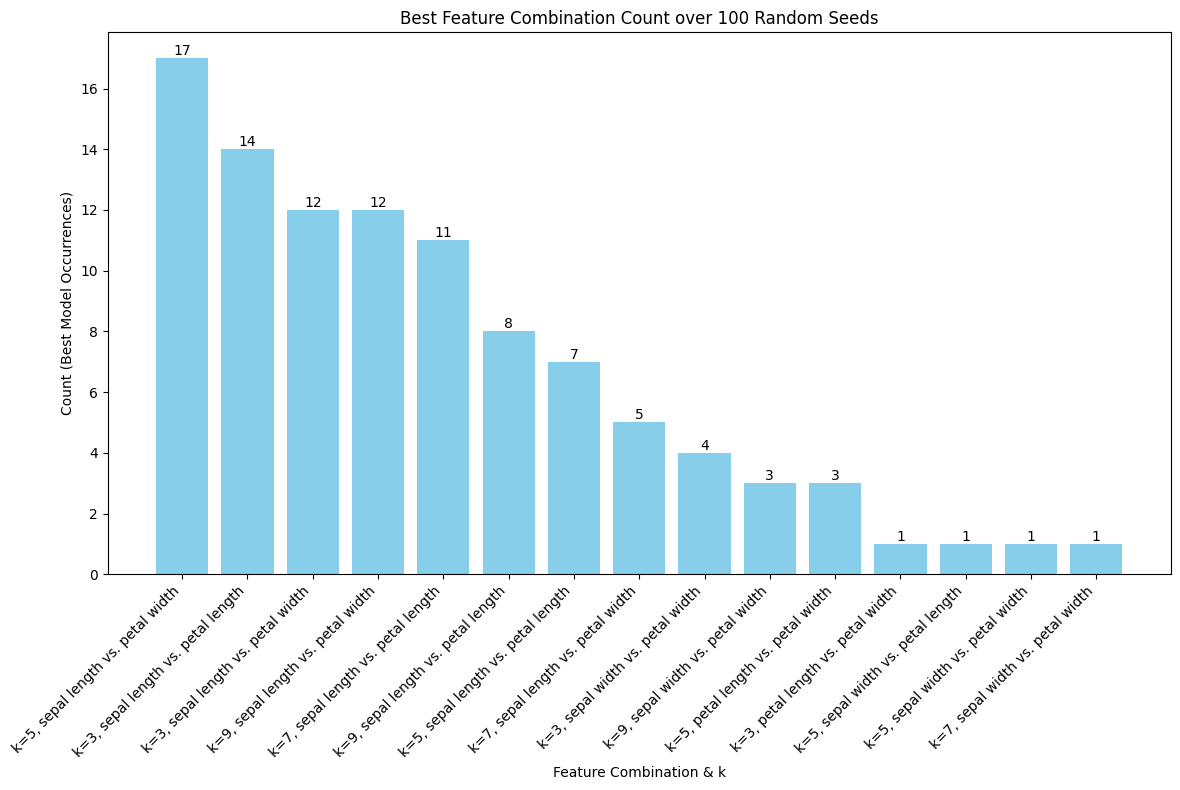

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningModel as mlm

data = np.genfromtxt("IrisDataset.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')

seed = 65

results = {}

for s in range(100):
    np.random.seed(seed + s)
    
    best_pair = {'acc': 0}
    for i in range(3):
        for j in range(i+1, 4):
            for k in [3, 5, 7, 9]:
                X = np.array([[r[i], r[j]] for r in data])
                y = np.array([r[4] for r in data])
                
                X_mean = np.mean(X, axis=0)
                X_std = np.std(X, axis=0)
                X = (X - X_mean) / X_std
                
                indices = np.random.permutation(len(X))
                X = X[indices]
                y = y[indices]
                
                X_train = X[: int(len(X) * 0.8)]
                y_train = y[: int(len(y) * 0.8)]

                X_test = X[int(len(X) * 0.8) :]
                y_test = y[int(len(y) * 0.8) :]

                knn = mlm.KNNClassificationModel(k)
                knn.fit(X_train, y_train)
                prediction = knn.predict(X_test)

                acc = knn.evaluate(y_test, prediction)
                if acc > best_pair['acc']:
                    best_pair = {'acc': acc, 'k': k, 'i': i, 'j': j}
    
    if (best_pair['k'], (best_pair['i'], best_pair['j'])) not in results:
        results[best_pair['k'], (best_pair['i'], best_pair['j'])] = 1 
    else:
        results[best_pair['k'], (best_pair['i'], best_pair['j'])] += 1
        
feature_names = {
    0: "sepal length",
    1: "sepal width",
    2: "petal length",
    3: "petal width"
}
    
sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
x_labels = [
    f"k={key[0]}, {feature_names[key[1][0]]} vs. {feature_names[key[1][1]]}"
    for key, _ in sorted_results
]
y_values = [count for _, count in sorted_results]

plt.figure(figsize=(12, 8))
bars = plt.bar(x_labels, y_values, color='skyblue')
plt.xlabel("Feature Combination & k")
plt.ylabel("Count (Best Model Occurrences)")
plt.title("Best Feature Combination Count over 100 Random Seeds")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()

2. **(Non-mandatory)** Implement a new Class called **FastKNNClassificationModel**. This method should be faster than your regular implementation. This can be done by using a faster data structure to look for the closest neighbors faster. In this assignment, you must build the KDTree with the the training data and then search for the neighbors using it.

* You must use this implementation of KDTree from Scipy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.KDTree.html
* The methods needed for your implementation are only the *constructor* (to build the KDTree) and the method *query* to find the k-neighbors.
* You must design an experiment using the **IrisDataset.csv** with **all features** to show that your new implementation is faster than your implementation of **KNNClassificationModel**.
* For example, you can measure the time using of each prediction, for each classifier, and plot the average time to give a decision for entries. Also, measure how this would increase/decrease with the increment of the input parameter *k*. 
* Use a plot(s) from matplotlib to support your answer.

**Discuss your findings for this question below**

After runnong both the FastKNNClassificationModel and KNNClassificationModel, we can see that using KDTree significantly improves the efficiency of the KNN algorithm. The KDTree structure optimised the code a lot especially for larger datasets or higher values of k.

From running the code on the Iris dataset, we can see that the FastKNNClassificationModel consistently outperformed the regular KNNClassificationModel in terms of prediction time. The time difference became more noticeable as the value of k increased, as the regular implementation requires a brute-force search, while the KDTree efficiently narrows down the search space.

The plots show that the average prediction time for the FastKNNClassificationModel is significantly lower than the regular implementation, demonstrating that KDTree datastructure helps with optimization.

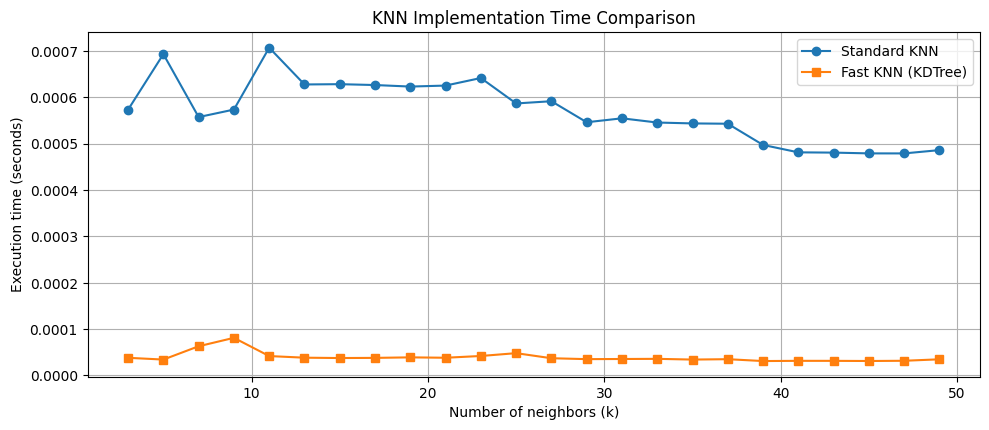

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import time
import MachineLearningModel as mlm

data = np.genfromtxt("IrisDataset.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')

X = np.array([[float(r[0]), float(r[1]), float(r[2]), float(r[3])] for r in data])
y = np.array([r[4] for r in data])

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X = (X - X_mean) / X_std

unique_labels = np.unique(y)
label_to_int = {label: i for i, label in enumerate(unique_labels)}
y = np.array([label_to_int[label] for label in y])

X_train = X[: int(len(X) * 0.8)]
y_train = y[: int(len(y) * 0.8)]
X_test = X[int(len(X) * 0.8):]
y_test = y[int(len(y) * 0.8):]

regular_times = []
fast_times = []
k_values = list(range(3, 50, 2))

for k in k_values:
    regular_knn = mlm.KNNClassificationModel(k)
    regular_knn.fit(X_train, y_train)
    
    start_time = time.time()
    regular_knn.predict(X_test)
    end_time = time.time()
    regular_time = end_time - start_time
    regular_times.append(regular_time / len(X_test))
    
    fast_knn = mlm.FastKNNClassificationModel(k)
    fast_knn.fit(X_train, y_train)
    
    start_time = time.time()
    fast_knn.predict(X_test)
    end_time = time.time()
    fast_time = end_time - start_time
    fast_times.append(fast_time / len(X_test))
    
        
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(k_values, regular_times, 'o-', label='Standard KNN')
plt.plot(k_values, fast_times, 's-', label='Fast KNN (KDTree)')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Execution time (seconds)')
plt.title('KNN Implementation Time Comparison')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Exercise 4: MNIST k-NN classification (Non-mandatory)

In this final exercise, we will use k-NN for classifying handwritten digits using the very famous MNIST dataset. Input to the algorithm is an image (28x28 pixel) with a handwritten digit (0-9) and the output should be a classification 0-9. The dataset and a description of it is available at http://yann.lecun.com/exdb/mnist/. Google MNIST Python to learn how to access it. The objective is to use your k-NN classifier to perform as good as possible on recognizing handwritten images. Describe your effort and what you found out to be the best k to lower the test error. The complete dataset has 60,000 digits for training and 10,000 digits for testing. Hence the computations might be heavy, so start of by a smaller subset rather than using the entire dataset. The final testing should (if possible) be done for the full test set but we will accept solutions that use "only" 10,000 digits for training and 1,000 digits for testing.
The description of this exercise is deliberately vague as you are supposed to, on your own, find a suitable way to solve this problem in detail. This is why it is important that you document your effort and progress in your report. **You must use your implementations of KNN for classification. If you successfully finished Exercise 3, part 2, it is advisable to use your FastKNNClassificationModel**


I took a subset of MNIST (10,000 training and 1,000 testing images) to keep computation manageable, as the full dataset was running way too long. I normaalized the pixel values to be in the [0,1] range. I then used my custom FastKNNClassificationModel to test for odd k values (from 3 to 49) and built an accuracy matrix for each digit class.

From the plot we can see that some digits (like 0 and 1) consistently showed high accuracy across different k, while others (like 2 and 8) were more sensitive to the choice of k. Overall, a smaller k (around 3 to 7) tended to perform the best, showing that using just a few nearest neighbors is sufficient for capturing the local structure in the MNIST data.

Looking at the plot here are some things I noticed:

- Digits 0 and 1 consistently show high accuracy across different k values. Their shapes are very distinct, so even with few neighbors their unique features are easily captured by the classifier.

- The digit 2 appears to be a bit more sensitive to the choice of k. This could be due to its structure having curved and diagonal elements which might sometimes resemble parts of other digits (like 3 or even 7) when written in different styles. A lower k helps keep the neighborhood focused on similar 2s, while higher k values might pull in noisy, less-similar neighbors from nearby classes, resulting to a less accurate result.

- Similar to 2, digit 8 shows variability with different k values. The challenge here might be its complexity and depending on the writing it can resemble other digits, such as 9 or even 3. Same as for 2, the lower k values helps to get more accurate results

- Digits like 3, 4, 5, 6, 7, and 9 show intermediate behavior, they are not as robust as 0 or 1, but they don't seem to be as drastically affected by k as 2 or 8. Again, a smaller k (around 3 to 7) typically provides enough local context without incorporating too many borderline examples from other digits.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import time
import MachineLearningModel as mlm

train_data = np.genfromtxt("mnist_train.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')
test_data = np.genfromtxt("mnist_test.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')

X_train_full = train_data[:, 1: ]
y_train_full = train_data[:, 0]

X_test_full = test_data[:, 1: ]
y_test_full = test_data[:, 0]

X_train_full = X_train_full / 255.0
X_test_full = X_test_full / 255.0

X_train = X_train_full[:10000]
y_train = y_train_full[:10000]
X_test = X_test_full[:1000]
y_test = y_test_full[:1000]


k_values = list(range(3, 50, 2))
digits = range(10)  
accuracy_matrix = np.zeros((len(digits), len(k_values)))

for i, k in enumerate(k_values):  
    knn = mlm.FastKNNClassificationModel(k)
    knn.fit(X_train, y_train)
    
    y_pred = knn.predict(X_test)    
    for j, digit in enumerate(digits):
        digit_indices = np.where(y_test == digit)[0]
        if len(digit_indices) > 0:
            digit_accuracy = np.sum(y_test[digit_indices] == y_pred[digit_indices]) / len(digit_indices)
            accuracy_matrix[j, i] = digit_accuracy * 100

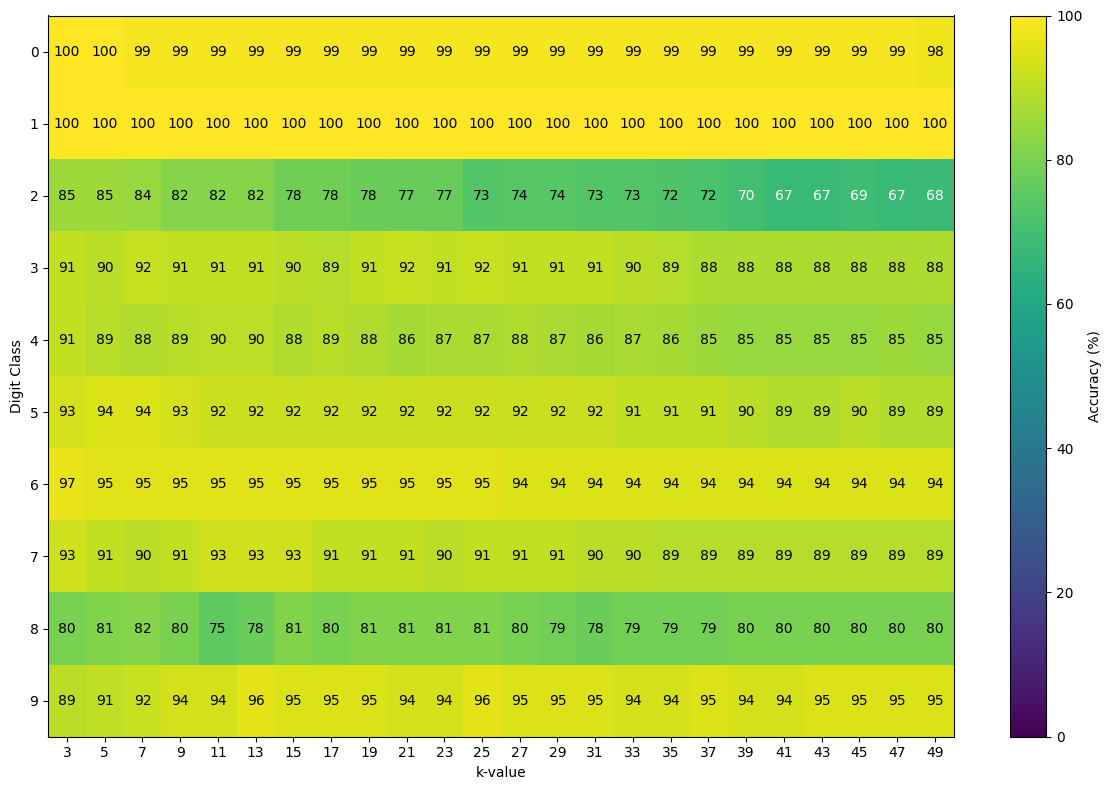

In [17]:

plt.figure(figsize=(12, 8))

im = plt.imshow(accuracy_matrix, cmap='viridis', aspect='auto', vmin=0, vmax=100)

cbar = plt.colorbar(im, label='Accuracy (%)')

plt.xlabel('k-value')
plt.ylabel('Digit Class')

plt.yticks(np.arange(len(digits)), digits)
plt.xticks(np.arange(len(k_values)), k_values)

for i in range(len(digits)):
    for j in range(len(k_values)):
        text = plt.text(j, i, f"{accuracy_matrix[i, j]:.0f}", 
                        ha="center", va="center", 
                        color="white" if accuracy_matrix[i, j] < 70 else "black")

plt.tight_layout()
plt.show()